### Check for wind

In [1]:
import requests

def get_wind_data(lat, lon, api_key):
    url = "http://api.openweathermap.org/data/2.5/weather"
    params = {
        'lat': lat,
        'lon': lon,
        'appid': api_key,
        'units': 'metric'
    }

    response = requests.get(url, params=params)
    data = response.json()
    print("🔍 API Response:", data)  # DEBUG LINE

    if 'wind' not in data:
        raise ValueError(f"❌ Wind data not found! Full response:\n{data}")

    wind_speed = data['wind']['speed']
    wind_direction = data['wind']['deg']
    
    return wind_speed, wind_direction

# Use your actual API key here
api_key = "6c77c4bd0f7280bf206a277dc5407cab"
lat, lon = 48.98, 8.26
vw, theta_w = get_wind_data(lat, lon, api_key)
print(f"✅ Wind Speed: {vw} m/s, Wind Direction: {theta_w}°")


🔍 API Response: {'coord': {'lon': 8.26, 'lat': 48.98}, 'weather': [{'id': 804, 'main': 'Clouds', 'description': 'overcast clouds', 'icon': '04d'}], 'base': 'stations', 'main': {'temp': 20.04, 'feels_like': 20.19, 'temp_min': 19.08, 'temp_max': 20.04, 'pressure': 1017, 'humidity': 80, 'sea_level': 1017, 'grnd_level': 1002}, 'visibility': 10000, 'wind': {'speed': 4.55, 'deg': 244, 'gust': 6.55}, 'clouds': {'all': 97}, 'dt': 1753953564, 'sys': {'type': 2, 'id': 2012243, 'country': 'DE', 'sunrise': 1753934310, 'sunset': 1753988882}, 'timezone': 7200, 'id': 2866074, 'name': 'Neuburg', 'cod': 200}
✅ Wind Speed: 4.55 m/s, Wind Direction: 244°


In [1]:
import copernicusmarine
ds = copernicusmarine.subset(
    dataset_id="cmems_mod_glo_phy-cur_anfc_0.083deg_PT6H-i",
    variables=["uo", "vo"],
    minimum_longitude=8,
    maximum_longitude=9,
    minimum_latitude=48,
    maximum_latitude=49,
    start_datetime="2025-07-01",
    end_datetime="2025-07-10"
)


c:\Users\nisha\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO - 2025-07-31T10:21:19Z - Selected dataset version: "202406"
INFO - 2025-07-31T10:21:19Z - Selected dataset part: "default"
INFO - 2025-07-31T10:21:24Z - Starting download. Please wait...
100%|██████████| 46/46 [00:01<00:00, 34.66it/s]
INFO - 2025-07-31T10:21:27Z - Successfully downloaded to cmems_mod_glo_phy-cur_anfc_0.083deg_PT6H-i_uo-vo_8.00E-9.00E_48.00N-49.00N_0.49-5727.92m_2025-07-01-2025-07-10.nc


In [2]:
import xarray as xr

ds = xr.open_dataset("cmems_mod_glo_phy-cur_anfc_0.083deg_PT6H-i_uo-vo_8.00E-9.00E_48.00N-49.00N_0.49-5727.92m_2025-07-01-2025-07-10.nc")
print(ds)


<xarray.Dataset> Size: 3MB
Dimensions:    (depth: 50, latitude: 13, longitude: 13, time: 37)
Coordinates:
  * depth      (depth) float32 200B 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 52B 48.0 48.08 48.17 ... 48.83 48.92 49.0
  * longitude  (longitude) float32 52B 8.0 8.083 8.167 8.25 ... 8.833 8.917 9.0
  * time       (time) datetime64[ns] 296B 2025-07-01 ... 2025-07-10
Data variables:
    uo         (time, depth, latitude, longitude) float32 1MB ...
    vo         (time, depth, latitude, longitude) float32 1MB ...
Attributes:
    Conventions:               CF-1.6
    contact:                   servicedesk.cmems@mercator-ocean.eu
    institution:               Mercator Ocean
    credit:                    E.U. Copernicus Marine Service Information (CM...
    producer:                  CMEMS - Global Monitoring and Forecasting Centre
    source:                    MERCATOR GLO12
    title:                     Instantaneous fields for product GLOBAL_ANA

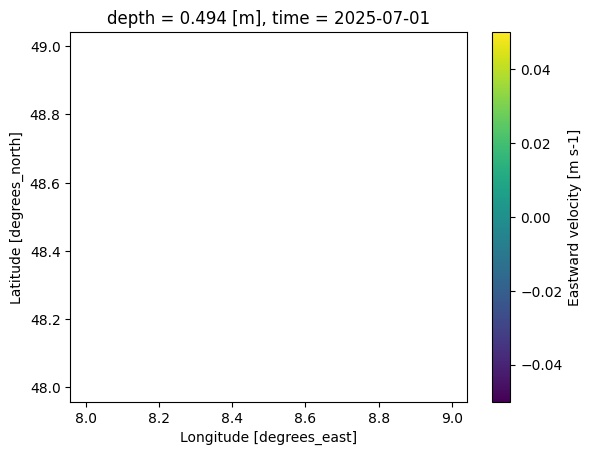

In [5]:
uo_surface = ds['uo'].isel(time=0, depth=0)  # u-component at surface and time=0
vo_surface = ds['vo'].isel(time=0, depth=0)  # v-component

uo_surface.plot()


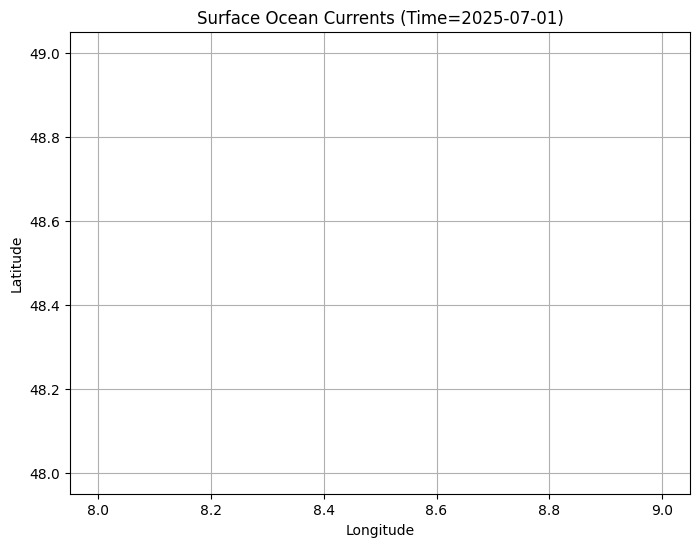

In [6]:
import matplotlib.pyplot as plt

lon = ds['longitude']
lat = ds['latitude']

plt.figure(figsize=(8, 6))
plt.quiver(lon, lat, uo_surface, vo_surface, scale=2)
plt.title("Surface Ocean Currents (Time=2025-07-01)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()
